In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import umap
import pandas as pd
from trafficking_inference.CellVADIS import (
    Stitch_OT,
    groundtruth_check,
    simulate_data,
    Joint_OT,
)
import trafficking_inference.helper_functions as hf
from simulator import marker_dict, location_dict, location_colors_dict

print(os.getcwd())
figure_path = "simulator/figures/"
data_path = "simulator/data/"
plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)

cm = 1 / 2.54  # centimeters in inches
dt = 0.02

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/wickerlw/Projects/OT_trafficking


In [2]:
n_hills_transition = 3
params = {
    "n_cells": 25000,  # Number of cells in the simulation
    "dt": 0.02,  # Time step (hours)
    "p_cd44_base": 5,  # Base CD44 expression rate
    "cd44_base_multiplier_sd": 0.4,  # SD for CD44 base rate multiplier
    "cd44_base_rate_multiplier_weight": 0.7,  # Weight for the base rate multiplier in CD44 expression
    "d_cd44_base": 0.1,  # CD44 degradation rate
    "p_cxcr4_base": 6,  # CXCR4 expression rate
    "cxcr4_base_multiplier_sd": 0.1,  # SD for CXCR4 base rate multiplier
    "cxcr4_base_rate_multiplier_weight": 0.2,  # Weight for the base rate multiplier in CXCR4 expression
    "d_cxcr4_base": 0.1,  # CXCR4 degradation rate
    "d_2_cxcr4": 0.5,  # Additional degradation rate for CXCR4 when in bone marrow
    "K_dwell_time_cxcr4": 16,  # Half-saturation constant for dwell time effect on CXCR4
    "n_hill_dwell_time_cxcr4": 4,  # Hill coefficient for dwell time effect on CXCR4
    "p_s1pr1_base": 12,  # S1PR1 expression rate
    "d_s1pr1_base": 0.1,  # S1PR1 degradation rate
    "s1pr1_base_multiplier_sd": 0.1,  # SD for S1PR1 base rate multiplier
    "d_2_s1pr1": 1,  # Additional degradation rate for S1PR1 when in blood
    "K_CD69_S1PR1": 60,  # Half-saturation constant for CD69 in the S1PR1 degradation
    "n_hill_cd69_s1pr1": 6,  # Hill coefficient for CD69 effect on S1PR1 degradation
    "K_dwell_time_s1pr1": 0.05,  # Half-saturation constant for dwell time effect on S1PR1
    "n_hill_dwell_time_s1pr1": 4,  # Hill coefficient for dwell time effect on S1PR1
    "p_ccr7_base": 8,  # CCR7 expression rate
    "ccr7_base_multiplier_sd": 0.1,  # SD for CCR7 base rate multiplier
    "ccr7_base_rate_multiplier_weight": 0.3,  # Weight for the base rate multiplier in CCR7 expression
    "d_ccr7_base": 0.1,  # CCR7 degradation rate
    "d_2_ccr7": 1,  # Additional degradation rate for CCR7 when in LN
    "K_dwell_time_ccr7": 8,  # Half-saturation constant for dwell time effect on CCR7
    "n_hill_dwell_time_ccr7": 4,  # Hill coefficient for dwell time effect on CCR7
    "p_cd69_base": 3,  # CD69 expression rate
    "d_cd69_base": 0.1,  # CD69 degradation rate
    "p_cd69_base_multiplier_sd": 0.5,  # SD for CD69 multiplier
    "cd69_base_rate_multiplier_weight": 0.8,  # Weight for the base rate multiplier in CD69 expression
    "p_cd62l_base": 8,  # CD62L expression rate
    "d_cd62l_base": 0.1,  # CD62L degradation rate
    "p_cd62l_base_multiplier_sd": 0.3,  # SD for CD62L multiplier
    "cd62l_base_rate_multiplier_weight": 0.3,  # Weight for the base rate multiplier in CD62L expression
    "p_a4b7_base": 4,  # a4b7 expression rate
    "d_a4b7_base": 0.1,  # a4b7 degradation rate
    "p_a4b7_base_multiplier_sd": 0.5,  # SD for a4b7 multiplier
    "a4b7_base_rate_multiplier_weight": 0.5,  # Weight for the base rate multiplier in a4b7 expression
    "blood_to_ln_rate": 30 * 2,  # Rate of transition from blood to lymph nodes
    "K_CCR7_blood_to_ln": 100,  # Half-saturation constant for CCR7 in the transition
    "K_CD62L_blood_to_ln": 130,  # Half-saturation constant for CD62L in the transition
    "n_hill_CCR7_blood_to_ln": n_hills_transition,  # Hill coefficient for CCR7 in blood to LN transition
    "n_hill_CD62L_blood_to_ln": n_hills_transition,  # Hill coefficient for CD62L in blood to LN transition
    "ln_to_blood_rate": 0.07,  # Rate of transition from lymph nodes to blood
    "K_S1PR1_ln_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "K_CCR7_ln_to_blood": 70,  # Half-saturation constant for CCR7 in the transition
    "n_hill_S1PR1_ln_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in LN to blood transition
    "n_hill_CCR7_ln_to_blood": n_hills_transition,  # Hill coefficient for CCR7 in LN to blood transition
    "spleen_to_blood_rate": 1.5,  # Rate of transition from spleen to blood
    "K_S1PR1_spleen_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_spleen_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in spleen to blood transition
    "blood_to_spleen_rate": 30 * 0.4,  # Rate of transition from blood to spleen
    "K_CCR7_blood_to_spleen": 100,  # Half-saturation constant for CCR7 in the transition
    "n_hill_CCR7_blood_to_spleen": n_hills_transition,  # Hill coefficient for CCR7 in blood to spleen transition
    "BM_to_blood_rate": 0.04,  # Rate of transition from bone marrow to blood
    "K_S1PR1_BM_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "K_CXCR4_BM_to_blood": 120,  # Half-saturation constant for CXCR4 in the transition
    "n_hill_S1PR1_BM_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in BM to blood transition
    "n_hill_CD44_BM_to_blood": n_hills_transition,  # Hill coefficient for CD44 in BM to blood transition
    "n_hill_CXCR4_BM_to_blood": n_hills_transition,  # Hill coefficient for CXCR4 in BM to blood transition
    "K_CD44_BM_to_blood": 100,  # Half-saturation constant for CD44 in the transition
    "blood_to_BM_rate": 30 * 0.2,  # Rate of transition from blood to bone marrow
    "K_CXCR4_blood_to_BM": 120,  # Half-saturation constant for CXCR4 in the transition
    "n_hill_CXCR4_blood_to_BM": n_hills_transition,  # Hill coefficient for CXCR4 in blood to BM transition
    "K_CD44_blood_to_BM": 90,  # Half-saturation constant for CD44 in the transition
    "n_hill_CD44_blood_to_BM": 2,  # Hill coefficient for CD44 in blood to BM transition
    "gut_to_blood_rate": 0.2,  # Rate of transition from gut to blood
    "K_S1PR1_gut_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_gut_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in gut to blood transition
    "blood_to_gut_rate": 30 * 0.2,  # Rate of transition from blood to gut
    "K_a4b7_blood_to_gut": 80,  # Half-saturation constant for a4b7 in the transition
    "n_hill_a4b7_blood_to_gut": n_hills_transition,  # Hill coefficient for a4b7 in blood to gut transition
    "K_S1PR1_blood_to_xx": 40,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_blood_to_xx": n_hills_transition,  # Hill coefficient for S1PR1 in blood to xx transition
}

In [ ]:
use_stored_data = True  # use stored_data to exactly reproduce the figures in the paper, or simulate new data with the same parameters
if use_stored_data:
    # Load simulation results
    true_next_locations_raw = np.load(data_path + "simulated_true_next_locations.npy")
    locations = np.load(data_path + "simulated_locations.npy")
    data_raw = np.load(data_path + "simulated_data_raw.npy")
    data_normalized = np.load(data_path + "simulated_data_normalized.npy")
else:
    # params = dict(zip(params.keys(), np.load("trafficking_inference/method_testing/results_run1/parameter_matrix.npy")[2]))
    data_raw, data_normalized, locations, true_next_locations_raw = simulate_data(
        params, procs=24, store_raw=True
    )


color_map = location_colors_dict

true_next_locations = true_next_locations_raw[
    locations == 2
]  # only consider cells starting in blood
real_fractions = np.zeros(4)
for j, loc in enumerate([1, 3, 4, 5]):
    real_fractions[j] = np.sum(true_next_locations == loc) / len(true_next_locations)

print("Real fractions for cells starting in blood:")
print(f"Blood to LN: {real_fractions[0]:.3f}")
print(f"Blood to spleen: {real_fractions[1]:.3f}")
print(f"Blood to BM: {real_fractions[2]:.3f}")
print(f"Blood to gut: {real_fractions[3]:.3f}")

print("#Cells per location currently:")
for j, loc in enumerate([1, 2, 3, 4, 5]):
    print(f"{location_dict[loc]}: {np.sum(locations == loc)}")

Real fractions for cells starting in blood:
Blood to LN: 0.519
Blood to spleen: 0.245
Blood to BM: 0.048
Blood to gut: 0.188
#Cells per location currently:
LN: 9946
Blood: 1332
Spleen: 1143
BM: 4271
Gut: 3183


In [4]:
data_source = data_normalized[locations == 2]  # only consider cells starting in blood
data_target = data_normalized[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = locations[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = np.array([location_dict[loc] for loc in target_locations])
source_name = "Blood"

target_names = ["LN", "Spleen", "BM", "Gut"]
fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Stitch_OT(
    data_source,
    data_target,
    target_locations,
    target_names,
    tau_a=0.5,
    subsample_non_blood=True,
    rescale_OT_plans=True,
    random_seed=5,
    epsilon=0.05,
)


data_source_raw = data_raw[locations == 2]  # only consider cells starting in blood
target_locations = target_locations[selected_target_mask]
fate_groups_ids = [1, 3, 4, 5]  # LN, Spleen, BM, Gut

stats = groundtruth_check(
    fate_matrix,
    OT_plan,
    data_source_raw,
    target_locations,
    target_names,
    params,
    true_next_locations,
    fate_groups_ids,
)
print(stats)

true_fate_probs = hf.get_true_fate_probabilities(data_source_raw, params)
true_fate_probs = true_fate_probs / true_fate_probs.sum(
    axis=1, keepdims=True
)  # normalize to sum to 1


hf.plot_accuracy_vs_threshold(
    fate_matrix,
    true_fate_probs,
    true_next_locations,
    fate_groups_ids=[1, 3, 4, 5],
    save_path=figure_path + "accuracy_vs_threshold_stitch.png",
)

[0.67792793 0.5508506  0.68438538 0.72844618 0.04818998 0.14587022
 0.18859111 0.18618619 0.18876553 0.148814   0.08660731 0.08177167
 0.1021021  0.43461833 0.30577903 0.15056907]


In [5]:
data_source = data_normalized[locations == 2]  # only consider cells starting in blood
data_target = data_normalized[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = locations[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = np.array([location_dict[loc] for loc in target_locations])
source_name = "Blood"
# subsample target locations to 20%
subsample_indices = np.random.choice(
    len(target_locations), size=int(len(target_locations) * 0.02), replace=False
)
target_locations = target_locations[subsample_indices]
data_target = data_target[subsample_indices]
target_names = ["LN", "Spleen", "BM", "Gut"]
(
    fate_matrix_jointOT,
    coupling_matrix_jointOT,
    OT_plan_jointOT,
    selected_target_mask_jointOT,
) = Joint_OT(
    data_source,
    data_target,
    target_locations,
    target_names,
    tau_b=0.5,
    subsample_non_blood=False,
    random_seed=5,
    epsilon=0.01,
)


data_source_raw = data_raw[locations == 2]  # only consider cells starting in blood
target_locations = target_locations[selected_target_mask_jointOT]
fate_groups_ids = [1, 3, 4, 5]  # LN, Spleen, BM, Gut

stats = groundtruth_check(
    fate_matrix_jointOT,
    OT_plan_jointOT,
    data_source_raw,
    target_locations,
    target_names,
    params,
    true_next_locations,
    fate_groups_ids,
)
print(stats)

[0.67792793 0.5508506  0.75415282 0.92019031 0.04818998 0.14587022
 0.18859111 0.18618619 0.09413091 0.09358498 0.10177848 0.09230572
 0.09084084 0.30085899 0.44261469 0.2084542 ]


## Figure 2

In [6]:
###  COMPUTE UMAP ###
reducer = umap.UMAP(n_neighbors=30, min_dist=1, n_jobs=9, random_state=42)
data_embedded = reducer.fit_transform(data_normalized)
data_embedded_blood = data_embedded[locations == 2]

colors = ["#a1c9f4", "#ff9f9b", "#ffb482", "#fab0e4", "#8de5a1"]
colors_outline = ["#0072B2", "#D55E00", "#E69F00", "#CC79A7", "#009E73"]
color_map_outline = {
    i: colors_outline[i - 1] for i in location_dict.keys()
}  # exclude blood color #Colors for true next location
# create a dict mapping colors to locations
color_dict = {
    location_dict[i]: colors[i - 1] for i in location_dict.keys()
}  # Colors for pie chart fill colors

# plot fate probabilities as pie charts on umap
frac = 0.05
cm = 1 / 2.54  # centimeters in inches
fig, ax = plt.subplots(figsize=(4.5, 4.5, "cm"), layout="constrained")


hf.plot_fate_probabilities_with_pie_charts(
    ax=ax,
    data_df=pd.DataFrame(data_embedded_blood, columns=["UMAP1", "UMAP2"]),
    probability_df=pd.DataFrame(
        fate_matrix, columns=["LN Fate", "Spleen Fate", "BM Fate", "Gut Fate"]
    ),
    entropy_fade=False,
    background=40,
    outline=4,
    colors=np.delete(colors, 1, 0),  # remove blood color
    s=350,
    n_cells_to_plot=75,  # Fraction of blood cells to plot, adjust depending on total number of blood cells for better visualization
    color_map=color_map_outline,
    locations=true_next_locations,
    plot_legend=False,
)

plt.xticks([])
plt.yticks([])
# remove all surrounding lines
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.savefig(
    figure_path + "umap_cell_fate_probabilities_stitchOT.pdf",
)
plt.close()


fig, ax = plt.subplots(figsize=(4.5, 4.5, "cm"), layout="constrained")
hf.plot_fate_probabilities_with_pie_charts(
    ax=ax,
    data_df=pd.DataFrame(data_embedded_blood, columns=["UMAP1", "UMAP2"]),
    probability_df=pd.DataFrame(
        fate_matrix_jointOT, columns=["LN Fate", "Spleen Fate", "BM Fate", "Gut Fate"]
    ),
    entropy_fade=False,
    background=40,
    outline=3.8,
    colors=np.delete(colors, 1, 0),  # remove blood color
    s=350,
    n_cells_to_plot=75,  # Fraction of blood cells to plot, adjust depending on total number of blood cells for better visualization
    color_map=color_map_outline,
    locations=true_next_locations,
    plot_legend=False,
)
plt.xticks([])
plt.yticks([])
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.savefig(
    figure_path + "umap_cell_fate_probabilities_jointOT.pdf",
)
plt.close()


# Do the same plot but with true fate matrix
data_blood_raw = data_raw[locations == 2]
true_fate_probabilities_total = hf.get_true_fate_probabilities(data_blood_raw, params)

true_fate_probabilities = (
    true_fate_probabilities_total
    / true_fate_probabilities_total.sum(axis=1, keepdims=True)
)

# plot fate probabilities as pie charts on umap
fig, ax = plt.subplots(figsize=(4.5 * cm, 4.5 * cm), layout="constrained")
hf.plot_fate_probabilities_with_pie_charts(
    ax=ax,
    data_df=pd.DataFrame(data_embedded_blood, columns=["UMAP1", "UMAP2"]),
    probability_df=pd.DataFrame(
        true_fate_probabilities,
        columns=["LN Fate", "Spleen Fate", "BM Fate", "Gut Fate"],
    ),
    entropy_fade=False,
    background=40,
    outline=3.8,
    colors=np.delete(colors, 1, 0),  # remove blood color
    s=350,
    n_cells_to_plot=75,
    color_map=color_map_outline,
    locations=true_next_locations,
    plot_legend=False,
)

plt.xticks([])
plt.yticks([])
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.savefig(
    figure_path + "umap_true_cell_fate_probabilities.pdf",
)
plt.close()


# create a legend and store seperately as pdf for later use
fig, ax = plt.subplots(figsize=(2.6 * cm, 2 * cm), layout="constrained")
legend_elements = [
    Patch(color=color_map[loc], label=f"{location_dict[loc]}") for loc in [1, 3, 4, 5]
]
# add one more legend entry showing a grey outline circle, meaning that the outlines represent the true next locations
legend_elements.append(
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="none",
        markeredgecolor="grey",
        label="True next location",
        linewidth=0.1,
    )
)
ax.legend(handles=legend_elements, title="Fate", fontsize=5)
ax.axis("off")
plt.savefig(
    figure_path + "fate_legend.pdf",
    transparent=True,
)
plt.close()

## Supplementary Figure 1

In [7]:
results = np.load(data_path + "simulated_data_raw_overtime.npy")
# only keep first 24 hours
results = results[: int(24 / dt), :, :]
# and subsample to 40000 cells for plotting
results = results[:, :40000, :]

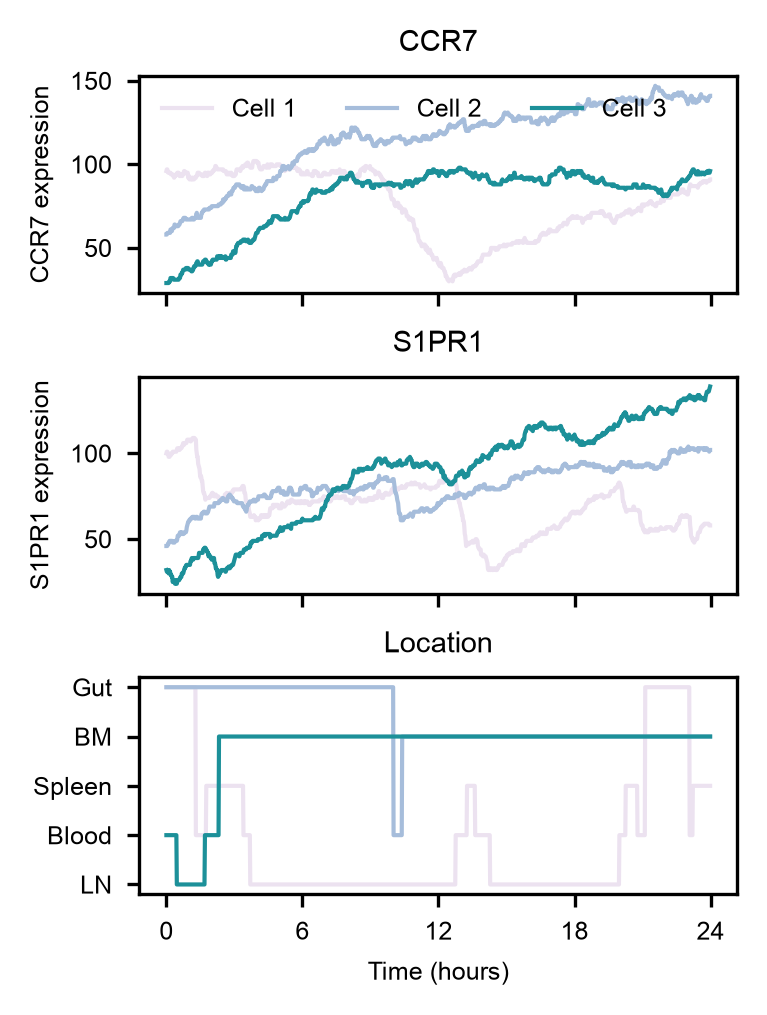

In [8]:
# Plot marker concentrations for 3 selected cells over time and their locations in one stacked figure
n_cells_to_plot = 3
np.random.seed(4)  # for reproducibility
random_cell_indices = [4, 20, 44]  # 33
time_points = np.arange(results.shape[0]) * dt
markers_to_plot = ["CCR7", "S1PR1"]
location_index = marker_dict["Location"]
# use seaborn deep palette
sns.set_palette("deep")
color_indices_list = [5, 6, 9]


deep_palette = sns.color_palette("deep", n_colors=max(color_indices_list) + 1)
colors = [deep_palette[idx] for idx in color_indices_list]

cell_colors = ["#ece2f0", "#a6bddb", "#1c9099"]
fig, axes = plt.subplots(
    3, 1, figsize=(6.2, 8.3, "cm"), sharex=True, layout="constrained"
)

for i, marker in enumerate(markers_to_plot):
    ax = axes[i]
    for j, cell_idx in enumerate(random_cell_indices):
        ax.plot(
            time_points,
            results[:, cell_idx, marker_dict[marker]],
            label=f"Cell {j + 1}",
            linewidth=1,
            color=cell_colors[j],
        )
    ax.set_title(f"{marker}")
    ax.set_ylabel(f"{marker} expression")
    # add legend to the first subplot (top left)
    if i == 0:
        ax.legend(loc="upper left", fontsize=6, frameon=False, ncols=3)
    # ax.tick_params(axis='both', which='major', length=5, width=1.5, labelsize=24)
    # ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ax = axes[2]
for i, cell_idx in enumerate(random_cell_indices):
    ax.plot(
        time_points,
        results[:, cell_idx, location_index],
        label=f"Cell {j + 1}",
        linewidth=1,
        color=cell_colors[i],
    )
ax.set_title("Location")
ax.set_yticks(list(location_dict.keys()), list(location_dict.values()))
ax.set_xticks([0, 6, 12, 18, 24])
ax.set_xlabel("Time (hours)")
fig.savefig(figure_path + "simulated_cell_markers_and_trajectories.pdf")
plt.show(fig)

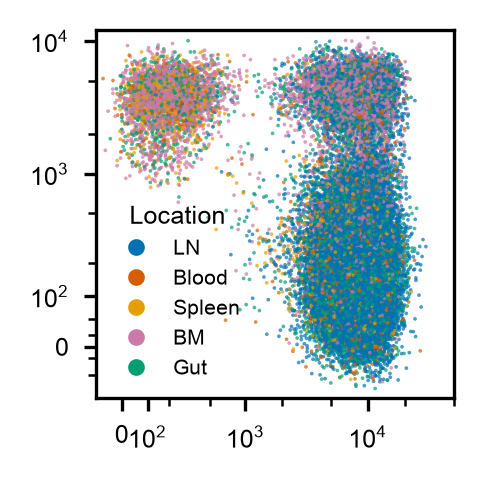

In [9]:
# Now do a conventional FACS scatter plot of CCR7 vs S1PR1 at the final time point, colored by location
final_time_point = results.shape[0] - 1
data_norm = results[:, :, :9] ** 1.8 + np.random.normal(
    0, 32, size=results[:, :, :9].shape
)
results_time_point = results[final_time_point, :, :]


# Now for CD62L vs CD44 again, but gate on CD44 positive cells
# Create color array, but only for cells passing the CD44 gate
cell_colors_cd62l_cd44 = np.array(
    [
        location_colors_dict[int(results_time_point[i, marker_dict["Location"]])]
        for i in range(results_time_point.shape[0])
    ]
)

plt.figure(figsize=(3.8, 3.8, "cm"), layout="constrained")
plt.scatter(
    data_norm[final_time_point, :, marker_dict["CD62L"]],
    data_norm[final_time_point, :, marker_dict["CD44"]],
    color=cell_colors_cd62l_cd44,
    alpha=0.7,
    s=0.8,
    edgecolors="none",
    linewidth=0,
    rasterized=True,
)

# Use asinh transformation for better visualization of the scatter plot
plt.xscale("asinh", linear_width=200)
plt.yscale("asinh", linear_width=100)
plt.xticks([0, 1e2, 1e3, 1e4, 1e5, 1e5])
plt.yticks([0, 1e2, 1e3, 1e4, 1e5, 1e5])
plt.ylim(-100, 1.2e04)
plt.xlim(-100, 5e04)
# plt.xlabel("CD62L")
# plt.ylabel("CD44")
# plt.tick_params(axis='both', which='major', length=5, width=1.5)
# the box around the plot should be thicker
# plt.tight_layout()
# add a legend for the colors
legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=location_dict[loc],
        markerfacecolor=location_colors_dict[loc],
        markersize=5,
    )
    for loc in location_dict.keys()
]
plt.legend(handles=legend_elements, title="Location", fontsize=5, frameon=False)

plt.savefig(figure_path + "facs_scatter_CD62L_CD44.pdf", dpi=600)
plt.show()

In [10]:
# Plot average marker expression per location in heatmap
# Calculate average marker expression per location
cells_location = results[1000, :, marker_dict["Location"]]
# plot pie chart of the distribution of cells across locations at the final time point
location_counts = np.bincount(cells_location.astype(int))[
    1:
]  # skip index 0 since it corresponds to "None"
location_labels = [location_dict[i] for i in range(1, len(location_dict) + 1)]
plt.figure(figsize=(3.5, 3.5, "cm"), layout="constrained")
plt.pie(
    location_counts,
    autopct="%1.0f%%",
    colors=[color_dict[loc] for loc in location_labels],
)
plt.savefig(figure_path + "location_distribution_pie_chart.pdf")
plt.close()

In [11]:
# Create a separate legend plot with transparent background
fig, ax = plt.subplots(figsize=(1.1 * cm, 1.5 * cm), layout="constrained")
ax.axis("off")  # Turn off the axes

# Create the handles and labels
handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color_dict[location_dict[loc]],
        markersize=5,
    )
    for loc in location_dict.keys()
]
labels = [location_dict[loc] for loc in location_dict.keys()]

# Create the legend
legend = ax.legend(handles, labels, title="Location", loc="center")

# Set transparent background
fig.patch.set_alpha(0)

# plt.tight_layout()
plt.savefig(figure_path + "legend_only.pdf", transparent=True)
plt.close()